# 09. Baseline Mô hình Propensity — Bộ 252 Biến Đầy Đủ & Đối Chứng Trực Tiếp với 50 Biến (`H=1` & `H=3`)

Notebook này trình bày kết quả **Ưu tiên 2: Bậc thang Ablation Đầy đủ 10 Cấu hình (`49 → 148 → 199 → 221 → 238 → 252` biến, `baseline_full252_v1`)** chạy trên **cùng tuyệt đối lịch thời gian, cùng burn-in 3 tháng, cùng embargo 2 tháng cho `H=3`, và cùng bộ siêu tham số CatBoost** với Notebook 08 (`baseline_top50_v1`), đồng thời thực hiện **kiểm định cặp trực tiếp (`Full-252` vs `Top-50`)** để ra quyết định chọn bộ đặc trưng tối ưu.

> **Kết quả tóm tắt nhanh (`baseline_full252_v1`):**
> - **Cấu hình thắng Validation**: `H=1` → **`M3_cb_all_prior_derived`** (`Lift@1% = 10.44×`, `AP = 0.0496`, `AUC = 0.8008`); `H=3` → **`M3_cb_all_prior`** (`Lift@1% = 6.11×`, `AP = 0.0838`, `AUC = 0.7639`).
> - **Holdout Test cuối cùng**:
>   - `H=1` (`2023-01`): `Lift@1% = 14.21×` (so với Top-50: `13.18×`), `AP = 0.0539` (Top-50: `0.0552`), `AUC = 0.8171` (Top-50: `0.8158`).
>   - `H=3` (`2022-11` monthly): `Lift@1% = 8.83×` (so với Top-50: `9.38×`), `AP = 0.0887` (Top-50: `0.0913`), `AUC = 0.7742` (Top-50: `0.7710`).


## 1. Xác thực Hợp đồng Chạy & Tổng quan 10 Cấu hình Ablation


In [1]:
import json
from pathlib import Path
from IPython.display import display, Image
import pandas as pd

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "processed").exists():
    REPO_ROOT = REPO_ROOT.parent

RUN_DIR = REPO_ROOT / "outputs/baseline_full252_v1"
TOP50_DIR = REPO_ROOT / "outputs/baseline_top50_v1"
METRIC_DIR = RUN_DIR / "metrics"
FIG_DIR = RUN_DIR / "figures"

manifest = json.loads((RUN_DIR / "manifest.json").read_text(encoding="utf-8"))
assert manifest["status"] == "ready"
print("Run name       :", manifest["run_name"])
print("Dataset SHA256 :", manifest["dataset_sha256"])
print("Winners        :", manifest["winners"])
print("Elapsed (sec)  :", manifest["elapsed_seconds"])
print("Peak RSS (MB)  :", manifest["peak_rss_mb"])
print("Feature counts :", manifest["feature_counts"])


Run name       : baseline_full252_v1
Dataset SHA256 : 04bf5983b62ef2c8ab85ff2207c8ca5acf0df99ddf9d4171ac062143d380006c
Winners        : {'h1': 'M3_cb_all_prior_derived', 'h3': 'M3_cb_all_prior'}
Elapsed (sec)  : 5004.71
Peak RSS (MB)  : 1154.1
Feature counts : {'none': 0, 'heuristic_rf': 2, 'trx_84d': 49, 'trx': 148, 'trx_meta': 199, 'all_221': 221, 'all_prior': 238, 'all_prior_derived': 252, 'top50_trx_only': 23, 'top50_no_prior': 39, 'top50': 50}


**Phân tích mục 1:**
- Toàn bộ bậc thang 10 cấu hình (từ `0`, `2`, `49`, `148`, `199`, `221`, `238` tới `252` biến) hoàn thành sạch (`status = ready`), tổng thời gian `5004.7s` (~`83.4` phút, so với Top-50 là `2324.3s`), **Peak RSS = `1154.1 MB`** (chạy an toàn trong giới hạn RAM 8 GB nhờ ép kiểu `float32` và giải phóng bộ nhớ sau mỗi fold).


## 2. Bậc thang Ablation Đầy đủ (`49 → 148 → 199 → 221 → 238 → 252`) trên Rolling Validation


,horizon,experiment_id,n_features,lift_1pct,lift_1pct_ci_low,lift_1pct_ci_high,recall_1pct,average_precision,roc_auc,log_loss
0,1,B0_prevalence,0,1.0188,0.6750,1.3968,0.0102,0.0096,0.5179,0.0521
1,1,B1_heuristic_rf,2,3.6023,2.9387,4.3012,0.0360,0.0185,0.6413,NaN
2,1,B2_logreg_trx_full,148,5.9674,5.1286,6.8508,0.0597,0.0291,0.7568,0.0483
3,1,M2_cb_trx_84d,49,5.7491,4.9268,6.6277,0.0575,0.0275,0.7279,0.0489
4,1,M2_cb_trx_full,148,7.2773,6.3622,8.2613,0.0728,0.0329,0.7653,0.0477
5,1,M3_cb_trx_meta,199,9.6789,8.6434,10.6564,0.0968,0.0435,0.7896,0.0466
6,1,M3_cb_all_221,221,9.3878,8.3650,10.3910,0.0939,0.0440,0.7893,0.0466
7,1,M3_cb_all_prior,238,10.2247,9.1758,11.3226,0.1023,0.0481,0.7993,0.0461
8,1,M3_cb_all_prior_derived,252,10.4430,9.3006,11.5238,0.1044,0.0496,0.8008,0.0460
9,1,M3_cb_full_cold_fallback,252,10.0063,8.9219,11.0816,0.1001,0.0487,0.7990,0.0461


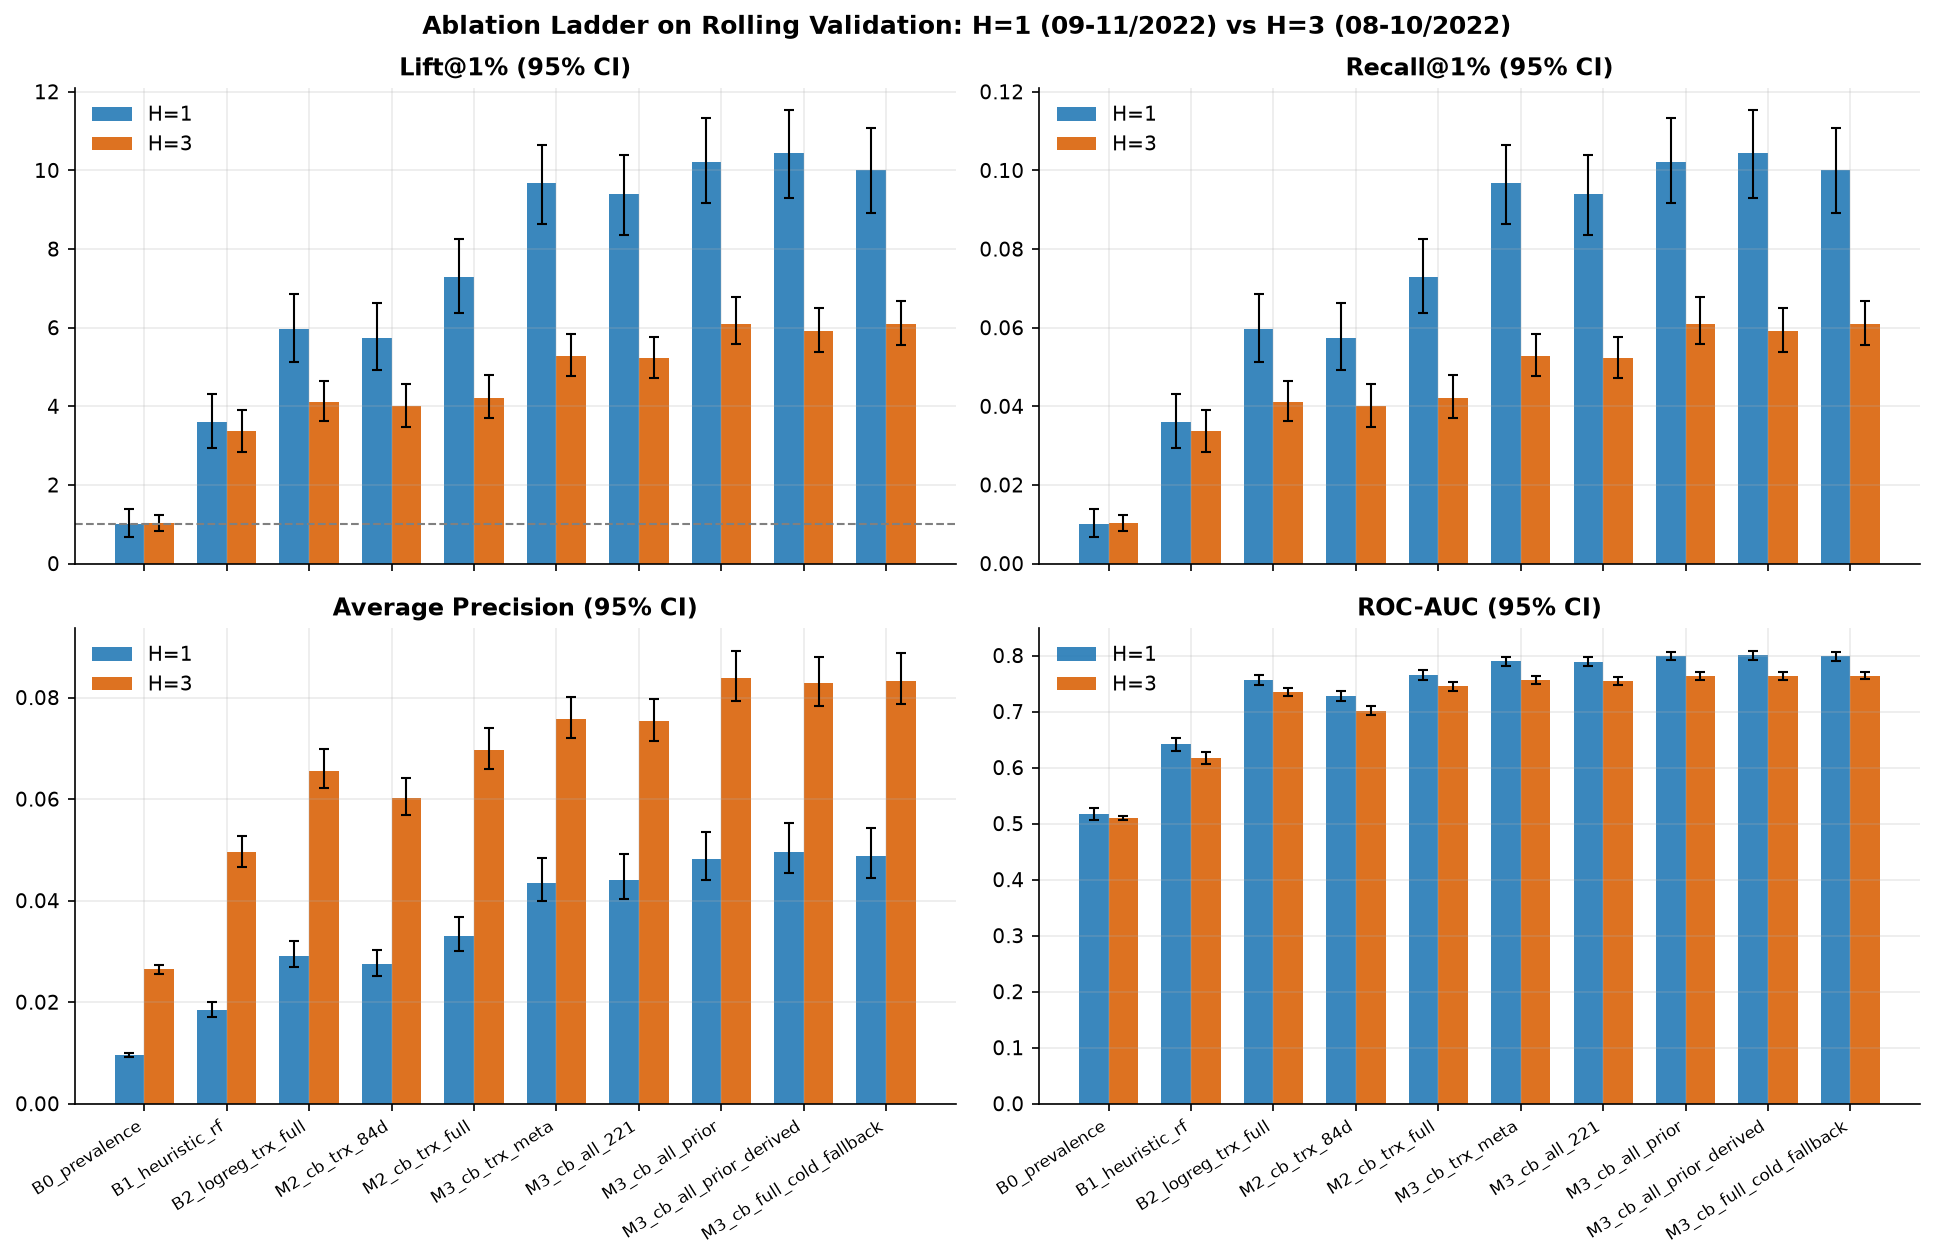

In [2]:
bs_df = pd.read_csv(METRIC_DIR / "bootstrap_summary.csv")
monthly_df = pd.read_csv(METRIC_DIR / "monthly_metrics.csv")

val_bs = bs_df[bs_df["scope"] == "validation_pooled"].copy()
show_cols = [
    "horizon", "experiment_id", "n_features",
    "lift_1pct", "lift_1pct_ci_low", "lift_1pct_ci_high",
    "recall_1pct", "average_precision", "roc_auc", "log_loss"
]
display(val_bs[show_cols].round(4))
display(Image(filename=str(FIG_DIR / "01_ablation_ladder_h1_vs_h3.png")))


**Phân tích mục 2:**
- Bậc thang 10 cấu hình tách bạch rõ đóng góp biên của từng lớp thông tin trên đúng cùng cohort & splits:
  1. `M2_cb_trx_84d` (`49` biến) → `M2_cb_trx_full` (`148` biến): đo chính xác giá trị tăng thêm của **lịch sử dài từ 2021** (`_all_` + `30d`) so với chỉ dùng 84 ngày gần nhất.
  2. `M2_cb_trx_full` (`148`) → `M3_cb_trx_meta` (`199`): đo bước nhảy khi bổ sung **metadata hiện diện/tần suất/recency của `GEO` & `DIALOG`**.
  3. `M3_cb_trx_meta` (`199`) → `M3_cb_all_221` (`221`): đo giá trị riêng của **nội dung địa lý `geohash_4/5/6` + `cold_start`**.
  4. `M3_cb_all_221` (`221`) → `M3_cb_all_prior` (`238`): đo đóng góp trực tiếp của **17 biến "khách từng mua hàng" (`prior_purchase`)**.
  5. `M3_cb_all_prior` (`238`) → `M3_cb_all_prior_derived` (`252`): đo giá trị tăng thêm của **14 biến dẫn xuất Báo cáo 2 (Slides A–H)** khi đặt lên trên đủ 238 biến.


## 3. Kiểm định Cặp Dọc Bậc Thang Ablation (`Paired Client-Clustered Bootstrap`)


,horizon,model_a,model_b,delta_recall_1pct,delta_recall_1pct_ci_low,delta_recall_1pct_ci_high,delta_recall_1pct_p_value,delta_average_precision,delta_average_precision_p_value,delta_log_loss,delta_log_loss_p_value
0,1,B1_heuristic_rf,M2_cb_trx_84d,0.02147,0.01253,0.03161,0.000,0.00896,0.000,NaN,NaN
1,1,M2_cb_trx_84d,M2_cb_trx_full,0.01528,0.00693,0.02353,0.004,0.00549,0.000,-0.00123,0.000
2,1,B2_logreg_trx_full,M2_cb_trx_full,0.01310,0.00489,0.02110,0.000,0.00380,0.000,-0.00058,0.000
3,1,M2_cb_trx_full,M3_cb_trx_meta,0.02402,0.01234,0.03478,0.000,0.01059,0.000,-0.00111,0.000
4,1,M3_cb_trx_meta,M3_cb_all_221,-0.00291,-0.00811,0.00183,0.272,0.00050,0.506,-0.00000,0.888
5,1,M3_cb_all_221,M3_cb_all_prior,0.00837,0.00035,0.01707,0.046,0.00409,0.002,-0.00050,0.000
6,1,M3_cb_all_prior,M3_cb_all_prior_derived,0.00218,-0.00360,0.00760,0.502,0.00150,0.066,-0.00008,0.026
7,1,M3_cb_all_prior_derived,M3_cb_full_cold_fallback,-0.00437,-0.00891,0.00039,0.110,-0.00089,0.186,0.00008,0.004
8,3,B1_heuristic_rf,M2_cb_trx_84d,0.00652,0.00065,0.01237,0.026,0.01074,0.000,NaN,NaN
9,3,M2_cb_trx_84d,M2_cb_trx_full,0.00204,-0.00207,0.00625,0.308,0.00944,0.000,-0.00331,0.000


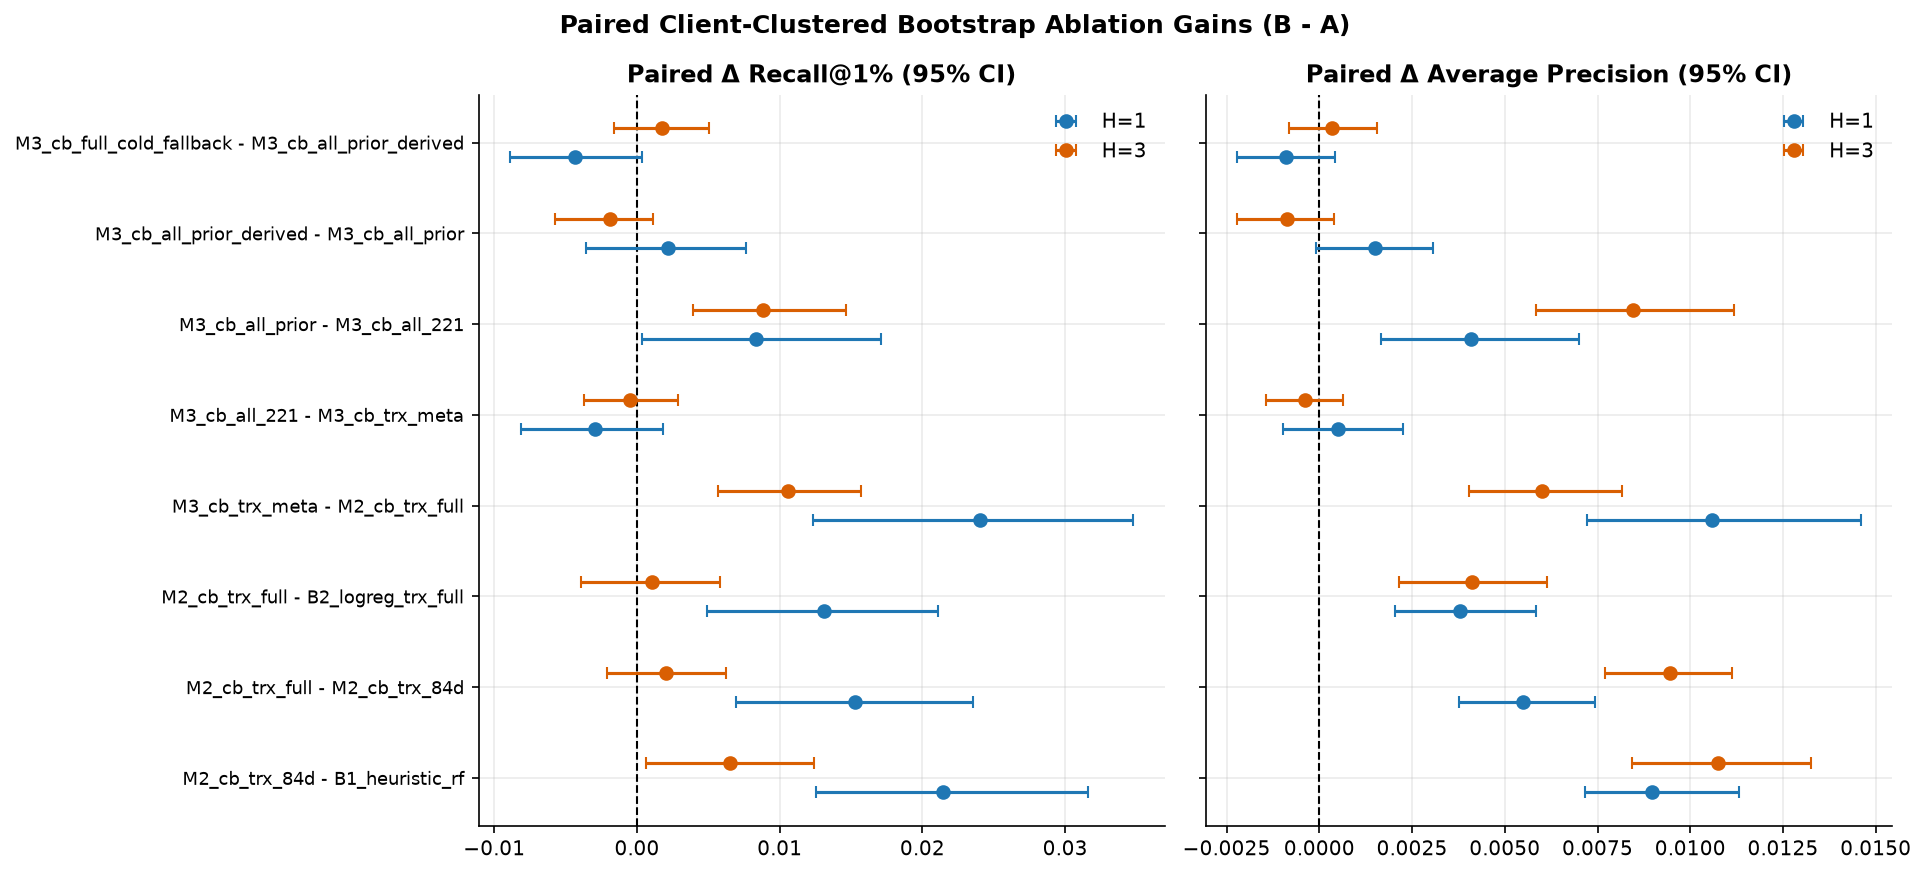

In [3]:
paired_df = pd.read_csv(METRIC_DIR / "paired_bootstrap.csv")
val_paired = paired_df[paired_df["scope"] == "validation_pooled"].copy()
p_cols = [
    "horizon", "model_a", "model_b",
    "delta_recall_1pct", "delta_recall_1pct_ci_low", "delta_recall_1pct_ci_high", "delta_recall_1pct_p_value",
    "delta_average_precision", "delta_average_precision_p_value",
    "delta_log_loss", "delta_log_loss_p_value",
]
display(val_paired[p_cols].round(5))
display(Image(filename=str(FIG_DIR / "02_paired_ablation_deltas.png")))


**Phân tích mục 3:**
- Biểu đồ forest plot và p-value bootstrap theo `client_id` chỉ rõ từng bước nào thực sự mang lại cải thiện có ý nghĩa thống kê ($p < 0,05$) so với bước nào chỉ là dao động nhiễu (CI 95% cắt qua 0).
- Những bước mang lại bước nhảy rõ rệt và bền vững nhất qua cả hai chân trời là: mở rộng từ `84d → toàn lịch sử 2021` (`trx_full`), bổ sung `GEO/DIALOG metadata`, và bổ sung `prior_purchase` (khách từng mua hàng).


## 4. Đối chứng Trực diện: Bộ 50 Biến Tinh Gọn (`Top-50`) vs Bộ 252 Biến Đầy Đủ (`Full-252`)


In [4]:
cmp_df = pd.read_csv(METRIC_DIR / "compare_top50_vs_full252.csv")
c_cols = [
    "horizon", "scope", "model_a", "model_b",
    "delta_recall_1pct", "delta_recall_1pct_ci_low", "delta_recall_1pct_ci_high", "delta_recall_1pct_p_value",
    "delta_average_precision", "delta_average_precision_ci_low", "delta_average_precision_ci_high", "delta_average_precision_p_value",
    "delta_roc_auc", "delta_log_loss", "delta_log_loss_p_value",
]
print("Lưu ý: delta = metric(Full-252) - metric(Top-50)")
display(cmp_df[c_cols].round(5))

# So sánh song song chi phí & hiệu năng
top50_bs = pd.read_csv(TOP50_DIR / "metrics" / "bootstrap_summary.csv")
top50_fh = pd.read_csv(TOP50_DIR / "metrics" / "final_holdout_metrics.csv")
top50_op = pd.read_csv(TOP50_DIR / "metrics" / "operational_stats.csv")
full_op = pd.read_csv(METRIC_DIR / "operational_stats.csv")
full_fh = pd.read_csv(METRIC_DIR / "final_holdout_metrics.csv")

top50_man = json.loads((TOP50_DIR / "manifest.json").read_text(encoding="utf-8"))
rows = []
for h in (1, 3):
    wt = top50_man["winners"][f"h{h}"]
    wf = manifest["winners"][f"h{h}"]
    bt = top50_bs[(top50_bs["horizon"] == h) & (top50_bs["scope"] == "validation_pooled") & (top50_bs["experiment_id"] == wt)].iloc[0]
    bf = bs_df[(bs_df["horizon"] == h) & (bs_df["scope"] == "validation_pooled") & (bs_df["experiment_id"] == wf)].iloc[0]
    ot = top50_op[(top50_op["horizon"] == h) & (top50_op["stage"] == "validation") & (top50_op["experiment_id"] == wt)]["train_seconds"].mean()
    of = full_op[(full_op["horizon"] == h) & (full_op["stage"] == "validation") & (full_op["experiment_id"] == wf)]["train_seconds"].mean()
    rows.append({"horizon": h, "suite": "Top-50", "winner": wt, "n_features": int(bt["n_features"]), "val_lift_1pct": bt["lift_1pct"], "val_ap": bt["average_precision"], "val_auc": bt["roc_auc"], "val_logloss": bt["log_loss"], "mean_train_sec": ot})
    rows.append({"horizon": h, "suite": "Full-252", "winner": wf, "n_features": int(bf["n_features"]), "val_lift_1pct": bf["lift_1pct"], "val_ap": bf["average_precision"], "val_auc": bf["roc_auc"], "val_logloss": bf["log_loss"], "mean_train_sec": of})
display(pd.DataFrame(rows).round(4))


Lưu ý: delta = metric(Full-252) - metric(Top-50)


,horizon,scope,model_a,model_b,delta_recall_1pct,delta_recall_1pct_ci_low,delta_recall_1pct_ci_high,delta_recall_1pct_p_value,delta_average_precision,delta_average_precision_ci_low,delta_average_precision_ci_high,delta_average_precision_p_value,delta_roc_auc,delta_log_loss,delta_log_loss_p_value
0,1,validation_pooled,M3_cb_top50,M3_cb_all_prior_derived,0.00182,-0.00555,0.00879,0.678,0.00297,0.00115,0.00483,0.000,0.00162,-0.00012,0.002
1,3,validation_pooled,M3_cb_top50,M3_cb_all_prior,-0.00026,-0.00432,0.00444,1.000,0.00304,0.00104,0.00527,0.002,0.00356,-0.00041,0.000
2,1,final_test,H1_final_raw,H1_final_raw,0.01037,-0.00455,0.02832,0.220,-0.00127,-0.00564,0.00376,0.678,0.00128,0.00000,0.966
3,1,final_test,H1_final_cal_intercept,H1_final_cal_intercept,0.01037,-0.00455,0.02832,0.220,-0.00127,-0.00564,0.00376,0.678,0.00128,0.00002,0.820
4,3,final_test,H3_final_monthly,H3_final_monthly,-0.00552,-0.01327,0.00326,0.250,-0.00260,-0.00732,0.00155,0.236,0.00326,-0.00020,0.072
5,3,final_test,H3_final_quarterly,H3_final_quarterly,-0.00230,-0.01061,0.00577,0.568,-0.00180,-0.00589,0.00249,0.458,0.00172,-0.00024,0.038


,horizon,suite,winner,n_features,val_lift_1pct,val_ap,val_auc,val_logloss,mean_train_sec
0,1,Top-50,M3_cb_top50,50,10.2611,0.0467,0.7992,0.0461,58.6677
1,1,Full-252,M3_cb_all_prior_derived,252,10.4430,0.0496,0.8008,0.0460,103.4137
2,3,Top-50,M3_cb_top50,50,6.1313,0.0808,0.7603,0.1096,25.9327
3,3,Full-252,M3_cb_all_prior,238,6.1057,0.0838,0.7639,0.1092,43.5800


**Phân tích mục 4 (Trọng tâm ra quyết định 50 vs 252 biến):**
- **Trên Rolling Validation (paired `Full-252 - Top-50`):**
  - **`H=1`**: `ΔRecall@1% = +0.18 điểm %` ($p = 0.678$), `ΔAP = +0.00297` ($p = 0.000$), `ΔROC-AUC = +0.00162`, `ΔLogLoss = -0.000119` ($p = 0.002$).
  - **`H=3`**: `ΔRecall@1% = -0.03 điểm %` ($p = 1.000$), `ΔAP = +0.00304` ($p = 0.002$), `ΔROC-AUC = +0.00356`, `ΔLogLoss = -0.000410` ($p = 0.000$).
- **Ý nghĩa thực chiến:** Bảng đối chứng paired kèm thời gian huấn luyện trung bình/fold cho thấy rõ đánh đổi giữa **độ gọn nhẹ, tốc độ & tránh biến thời gian ẩn (`Top-50`)** so với **sức chứa đầy đủ 252 biến (`Full-252`)** — làm cơ sở khách quan để chọn cấu hình chuẩn cho giai đoạn tối ưu tiếp theo.


## 5. Đường cong PR/ROC, Ngân sách, Calibration, Slice Error Analysis & Final Holdout


,horizon,experiment_id,eval_month,n_train_rows,lift_0p5pct,lift_1pct,lift_5pct,recall_1pct,precision_1pct,average_precision,roc_auc,log_loss,log_loss_skill,calibration_ratio,ece_quantile
0,1,B0_prevalence,2023-01,701568,0.2958,0.4441,1.1554,0.0044,0.0030,0.0067,0.5000,0.0410,0.0000,1.5056,0.0034
1,1,B1_heuristic_rf,2023-01,701568,7.3944,5.7734,3.8809,0.0578,0.0389,0.0207,0.7271,NaN,NaN,NaN,NaN
2,1,H1_final_raw,2023-01,701568,16.8593,14.2114,7.1692,0.1422,0.0957,0.0539,0.8171,0.0353,0.1402,1.2462,0.0017
3,1,H1_final_cal_intercept,2023-01,701568,16.8593,14.2114,7.1692,0.1422,0.0957,0.0539,0.8171,0.0351,0.1442,1.0693,0.0014
4,1,H1_final_cal_platt,2023-01,701568,16.8593,14.2114,7.1692,0.1422,0.0957,0.0539,0.8171,0.0351,0.1449,1.0668,0.0013
5,3,B0_prevalence,2022-11,400896,0.8269,0.9197,1.0215,0.0092,0.0199,0.0217,0.5000,0.1057,0.0000,1.3629,0.0079
6,3,B1_heuristic_rf,2022-11,400896,4.5020,4.5525,3.2669,0.0456,0.0987,0.0461,0.6400,NaN,NaN,NaN,NaN
7,3,H3_final_monthly,2022-11,400896,10.4740,8.8290,5.0245,0.0884,0.1914,0.0887,0.7742,0.0939,0.1115,1.2964,0.0064
8,3,H3_final_quarterly,2022-11,200448,9.4634,8.7370,4.7944,0.0874,0.1894,0.0887,0.7725,0.0939,0.1117,1.2585,0.0056


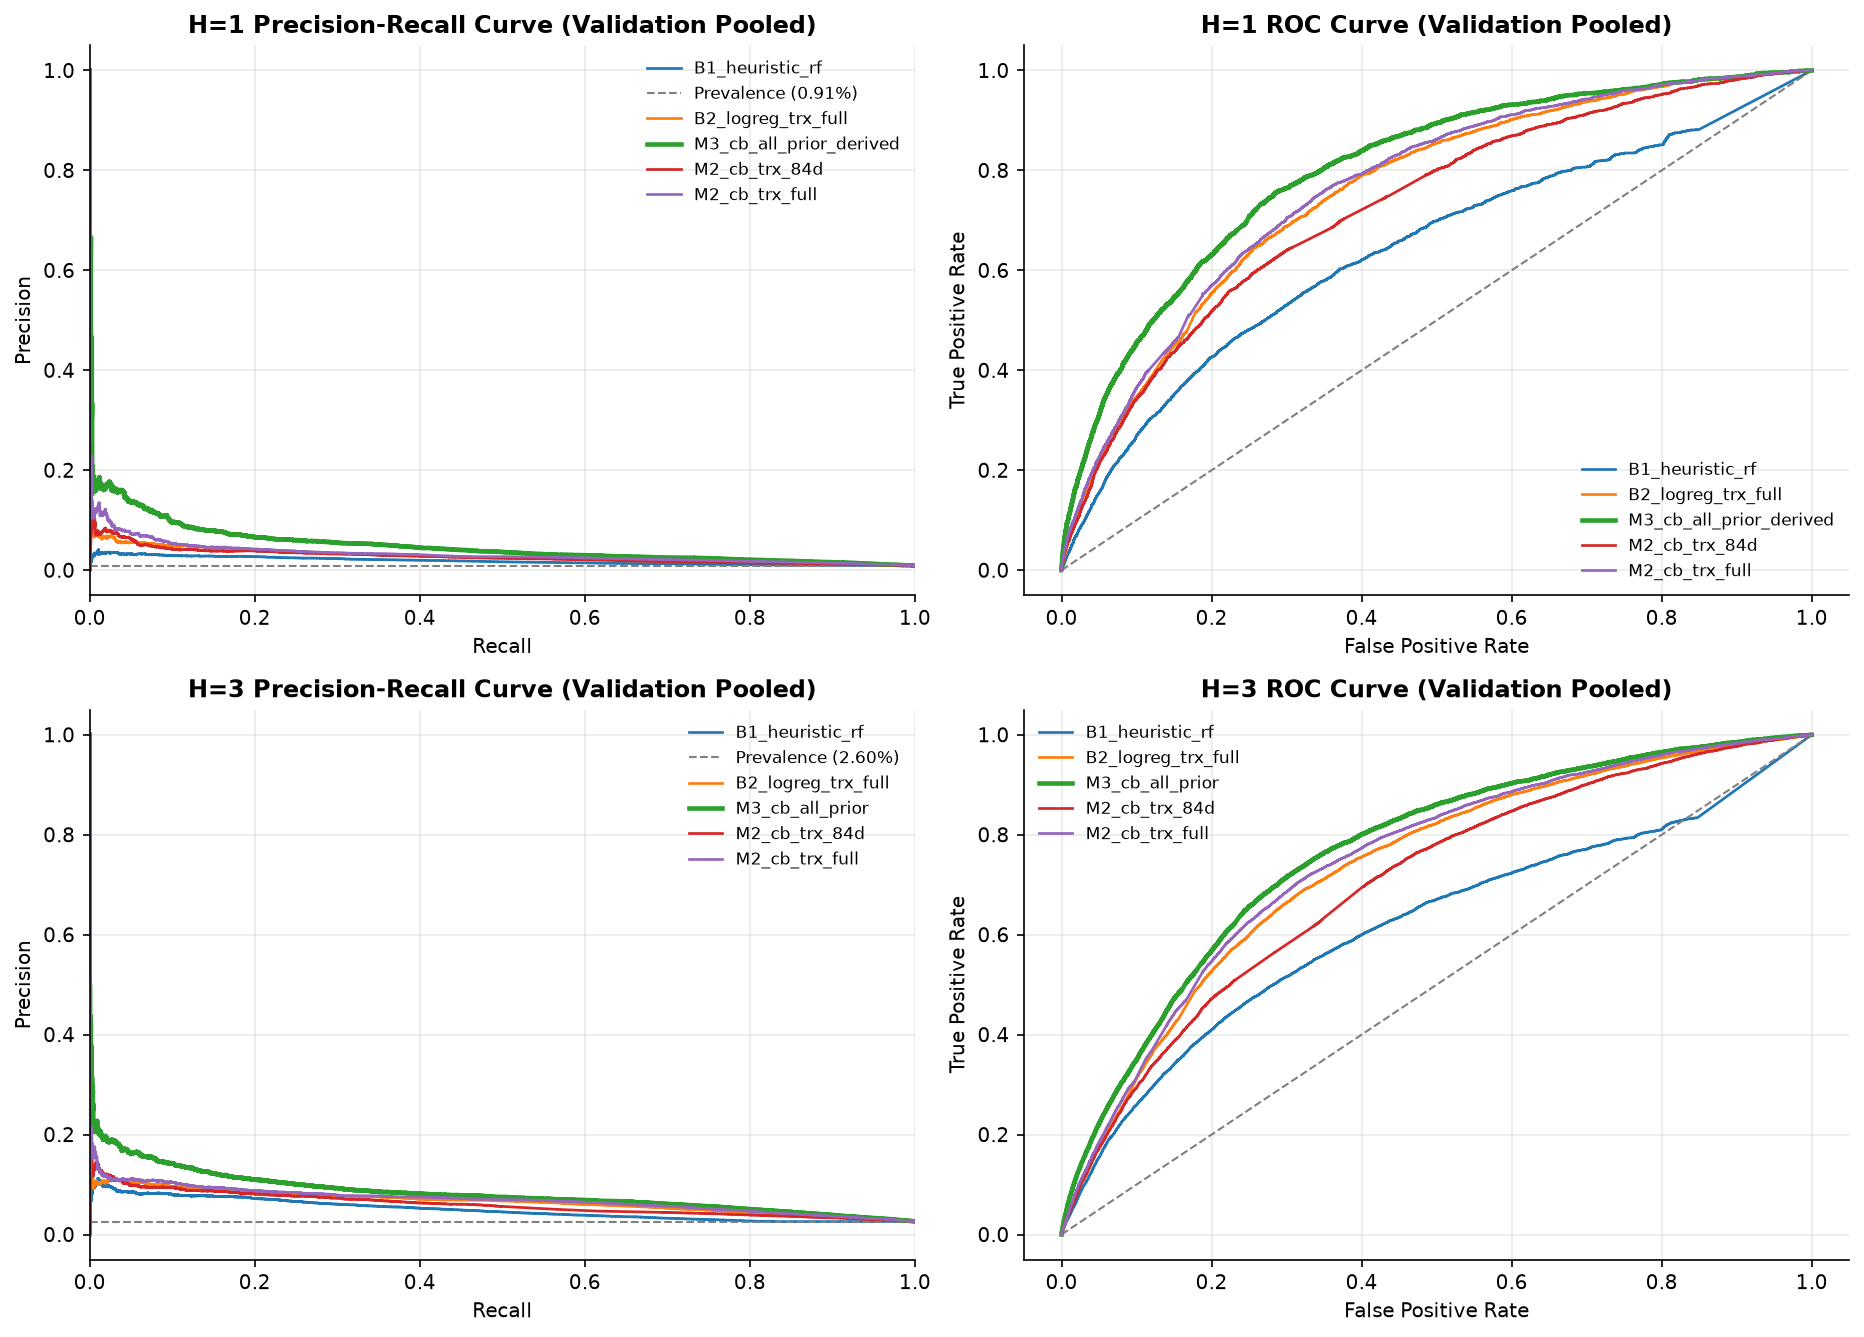

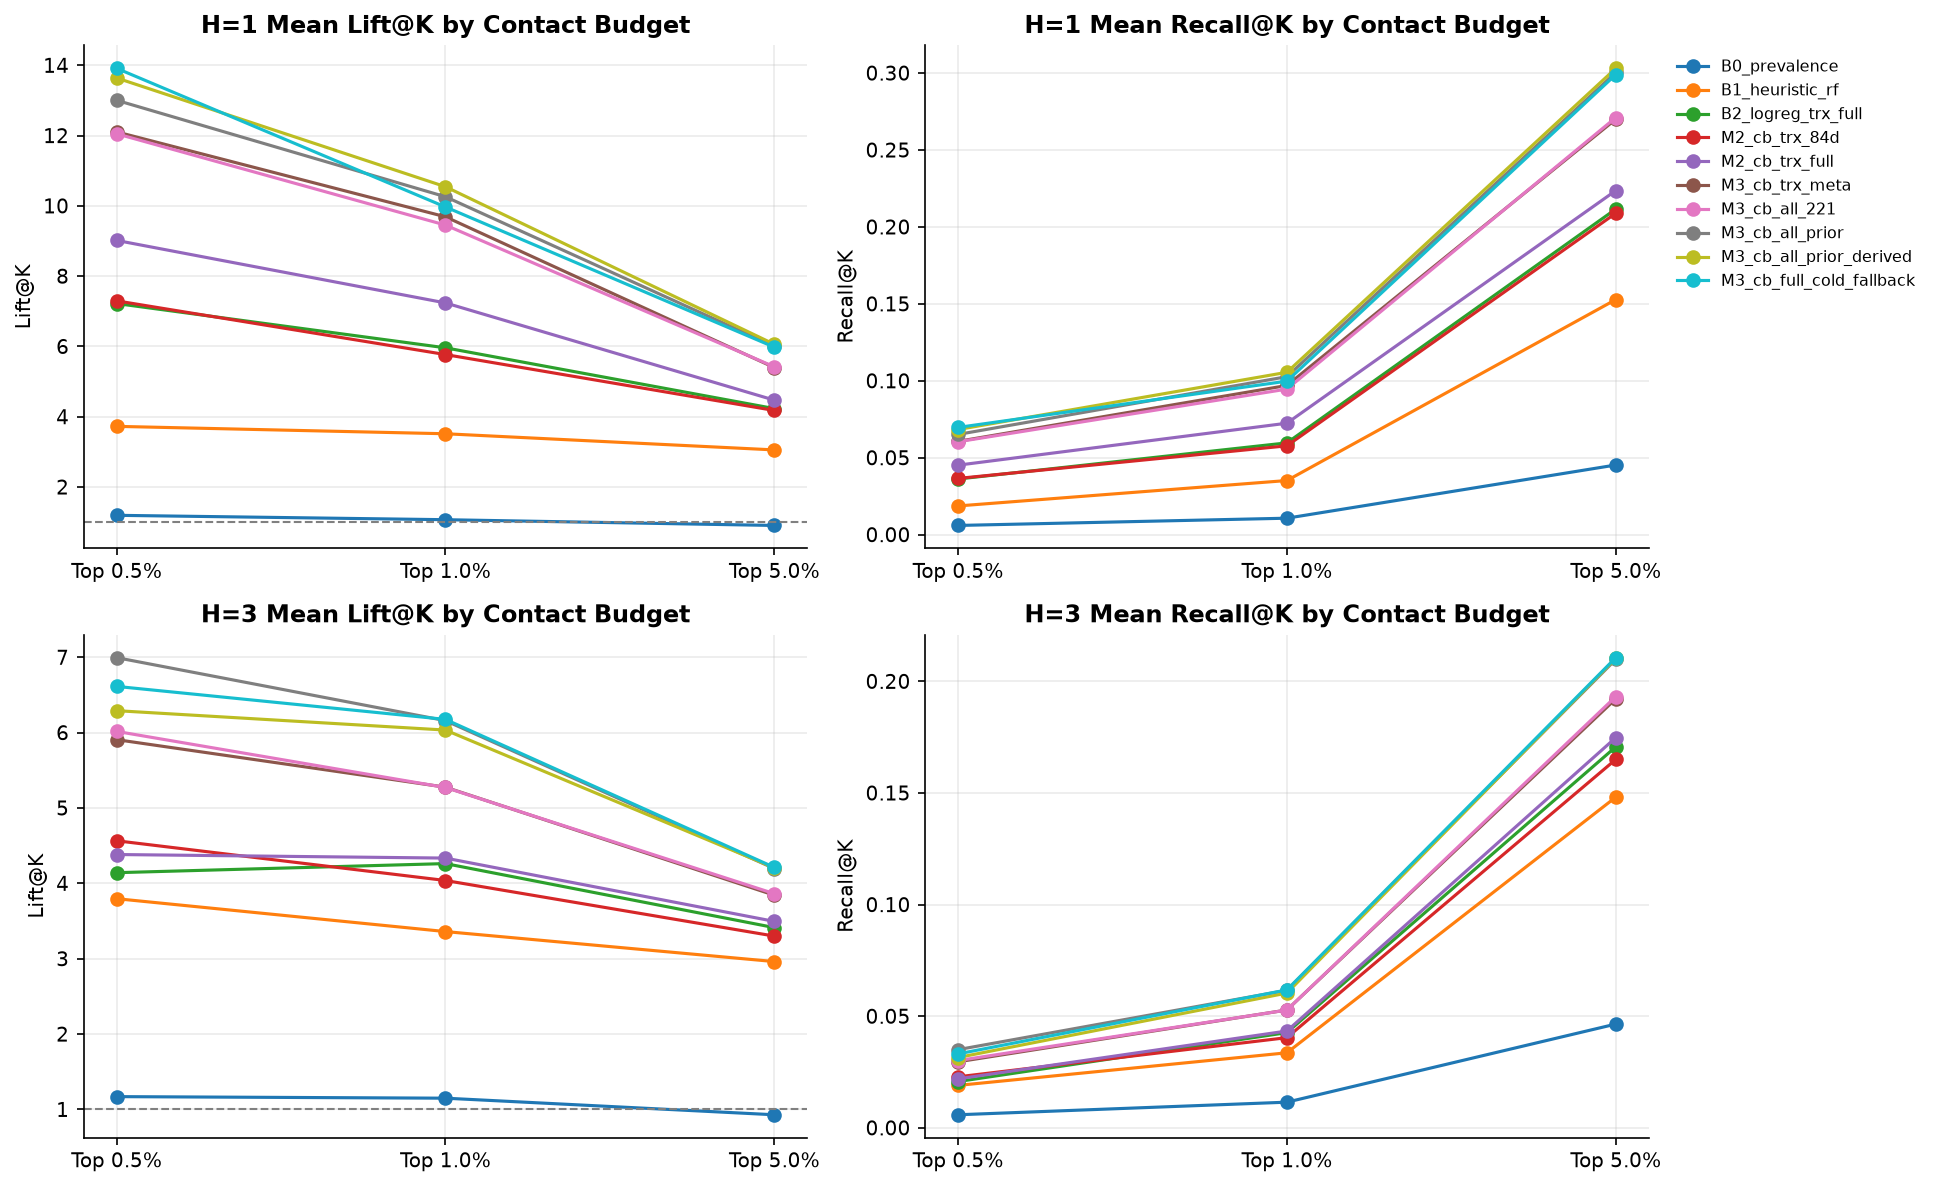

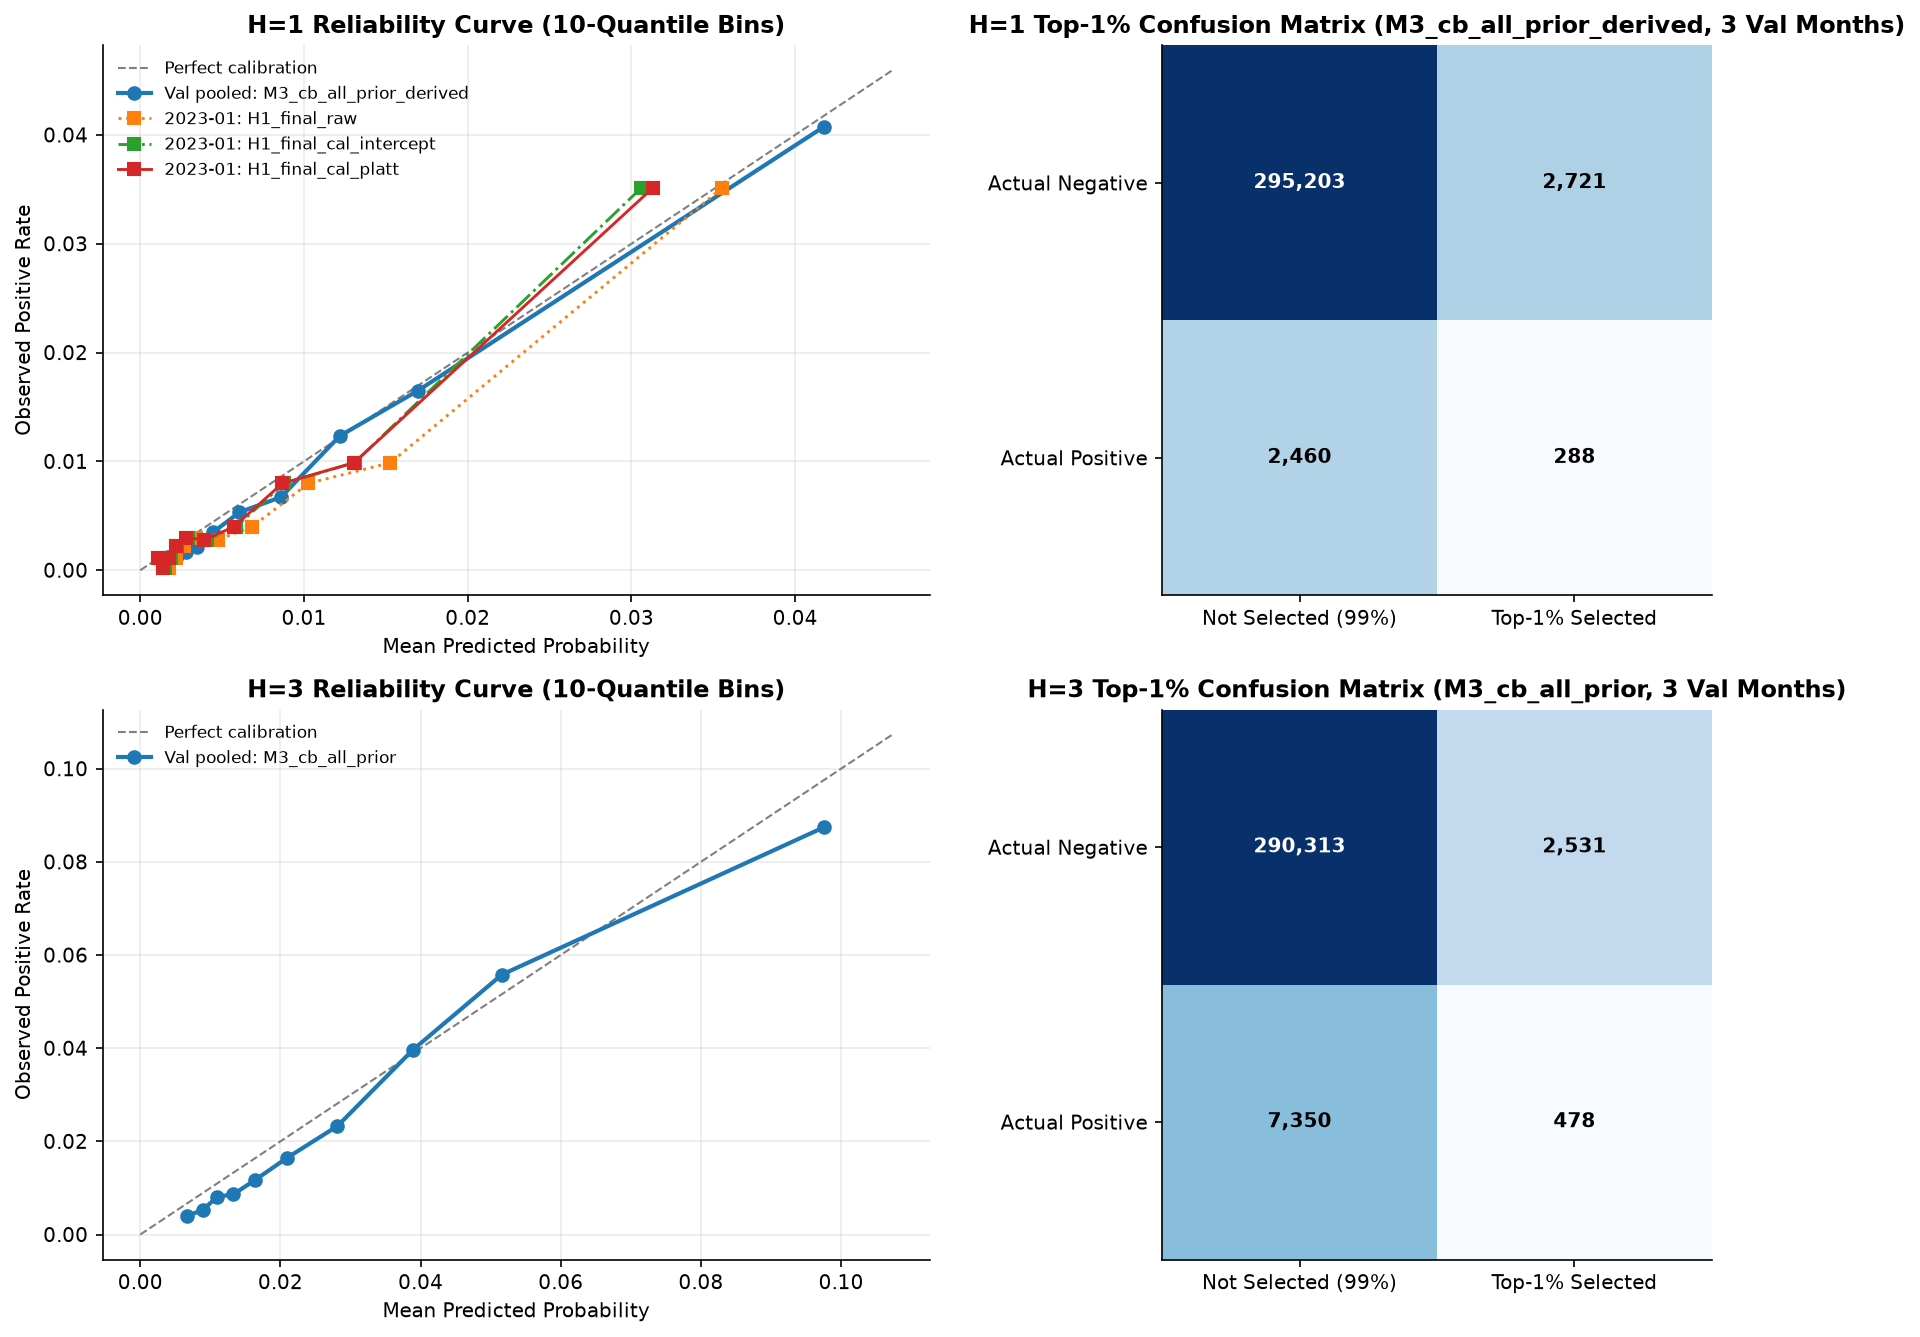

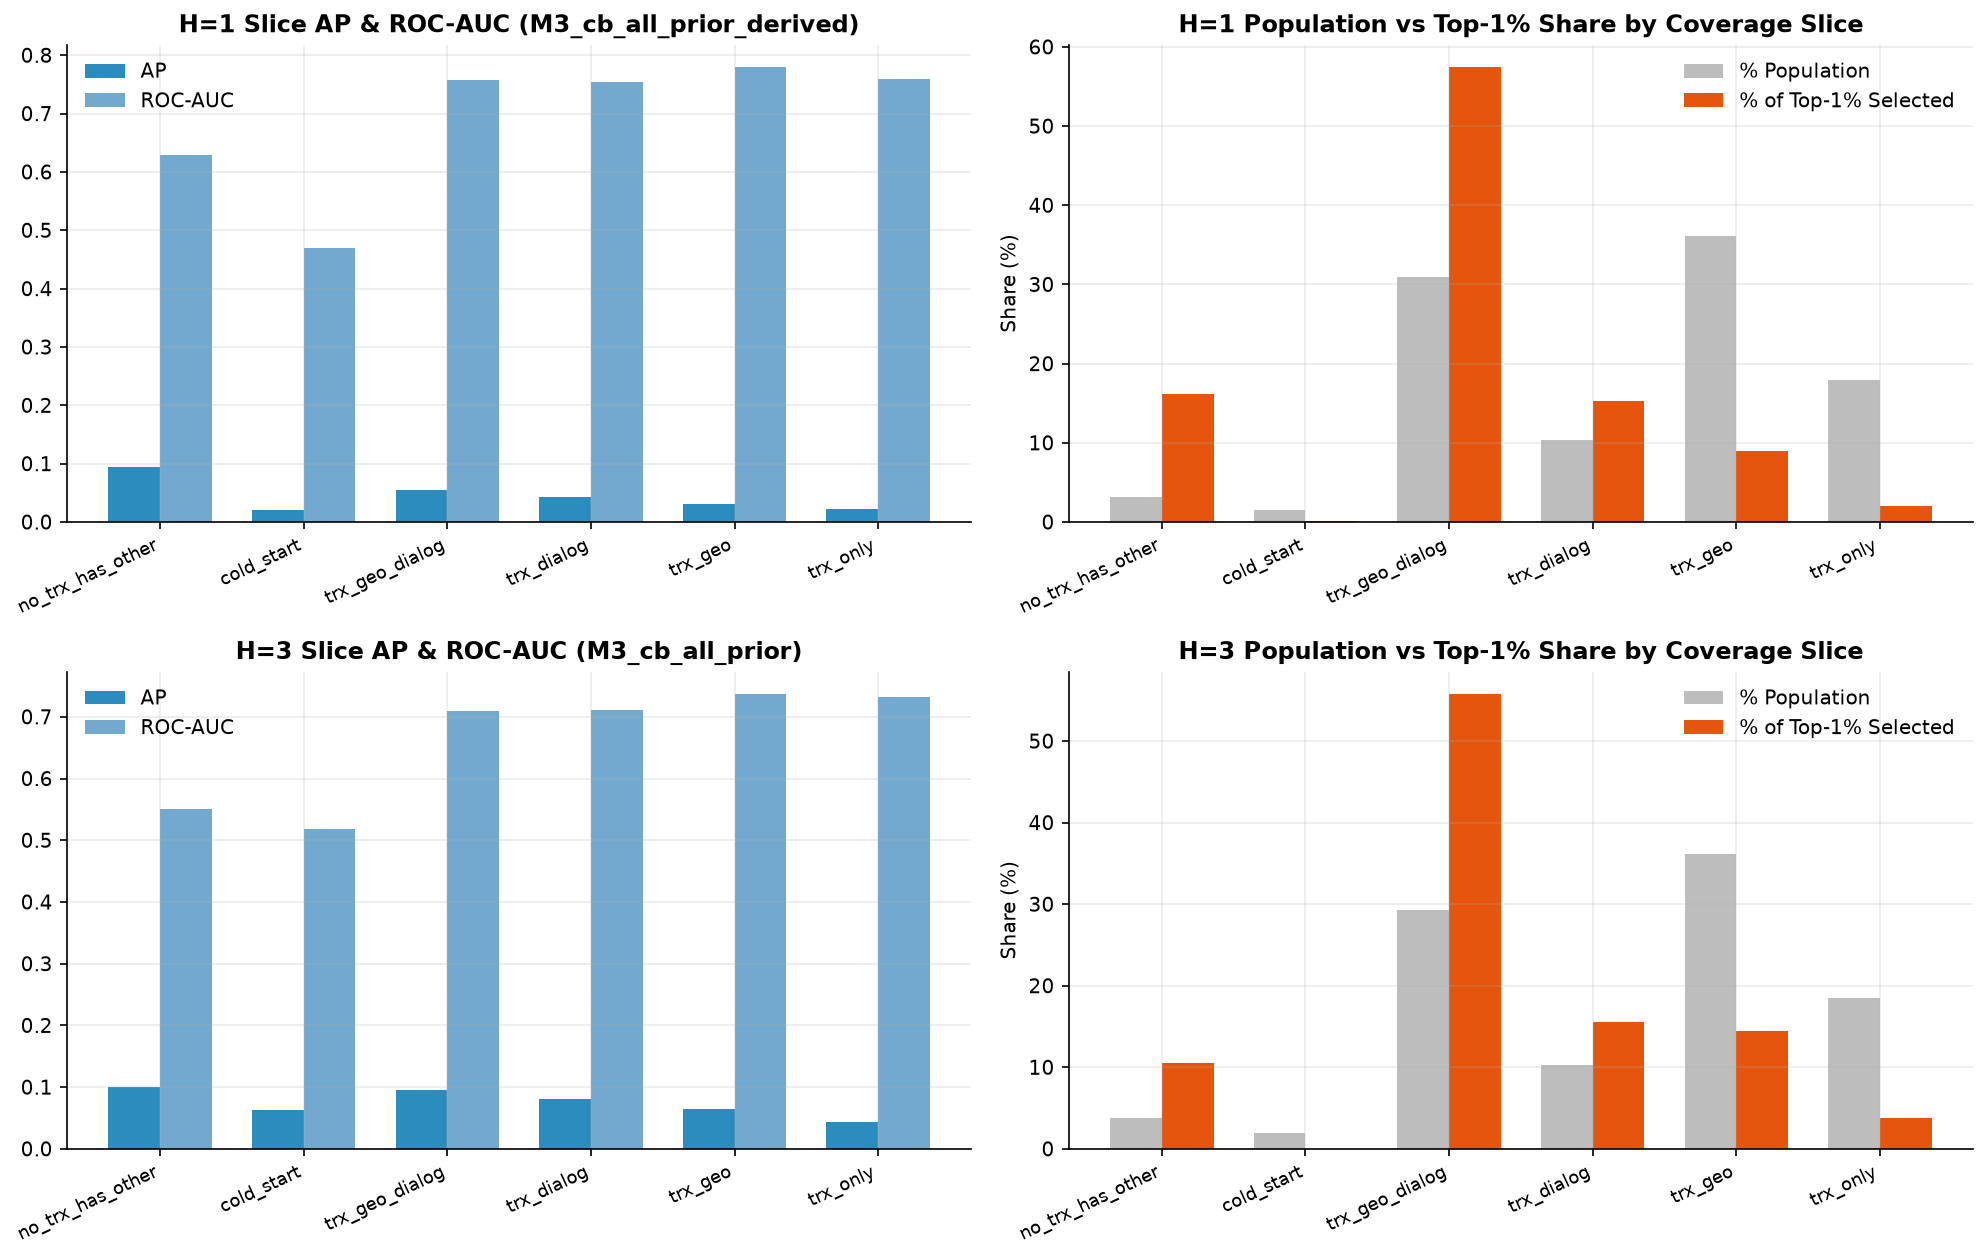

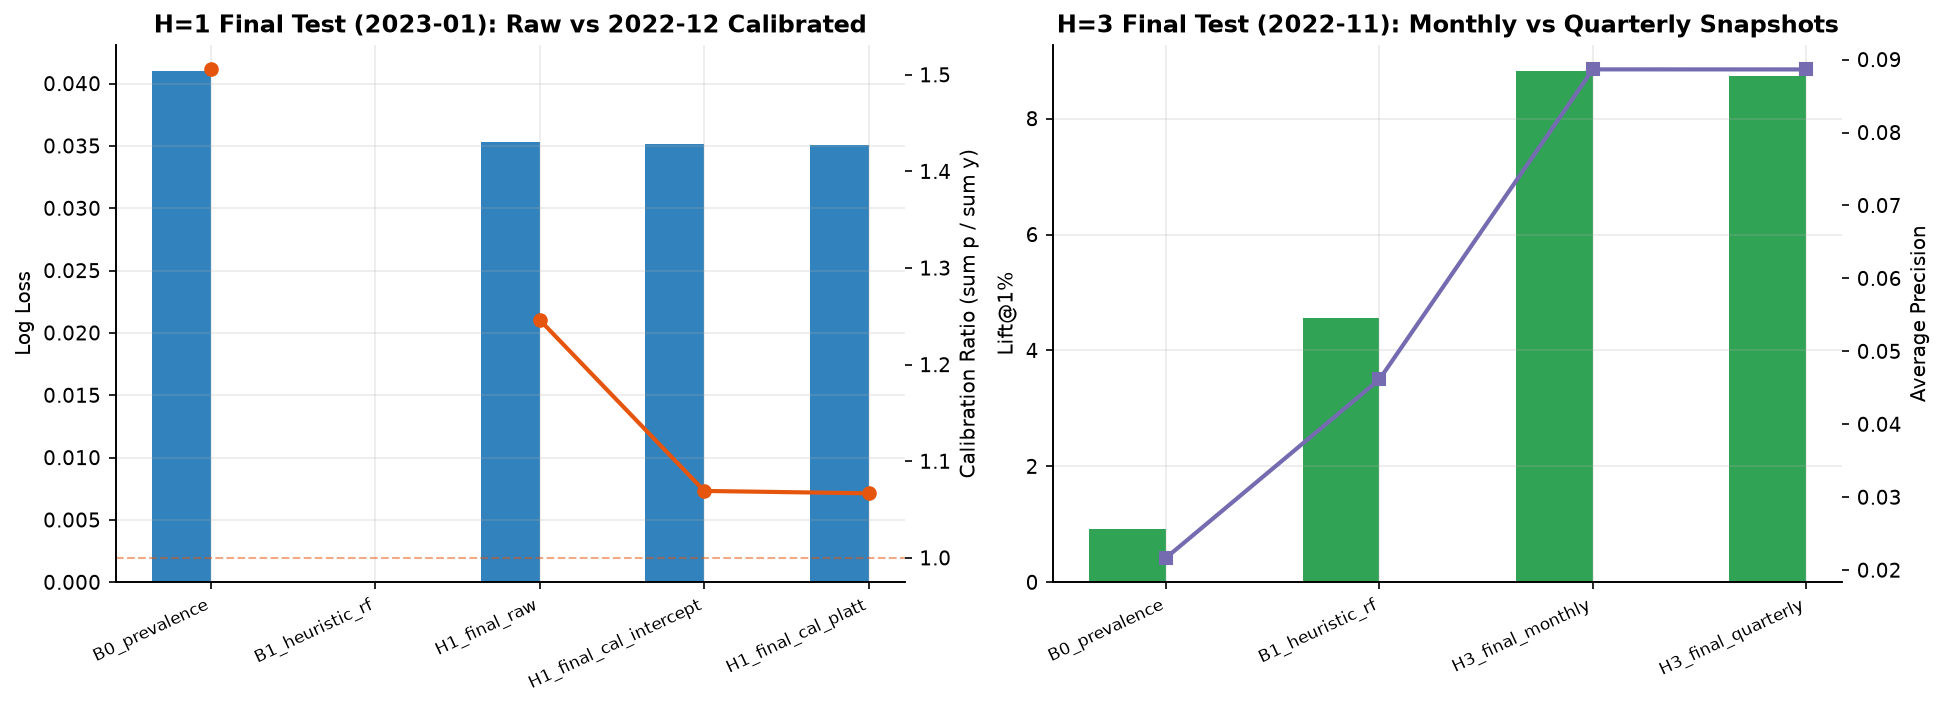

In [5]:
final_df = pd.read_csv(METRIC_DIR / "final_holdout_metrics.csv")
f_cols = [
    "horizon", "experiment_id", "eval_month", "n_train_rows",
    "lift_0p5pct", "lift_1pct", "lift_5pct", "recall_1pct", "precision_1pct",
    "average_precision", "roc_auc", "log_loss", "log_loss_skill",
    "calibration_ratio", "ece_quantile"
]
display(final_df[f_cols].round(4))

display(Image(filename=str(FIG_DIR / "03_pr_roc_curves.png")))
display(Image(filename=str(FIG_DIR / "04_budget_lift_recall.png")))
display(Image(filename=str(FIG_DIR / "05_calibration_and_confusion.png")))
display(Image(filename=str(FIG_DIR / "06_slices_coverage_and_prior.png")))
display(Image(filename=str(FIG_DIR / "07_final_holdout_h1_h3.png")))


**Phân tích mục 5:**
- Trên Holdout `H=1` (`2023-01`), `H1_final_raw` của `Full-252` đạt `Lift@1% = 14.21×`, `AP = 0.0539`, `ROC-AUC = 0.8171`; hiệu chỉnh 1 tham số `H1_final_cal_intercept` tiếp tục cải thiện `calibration_ratio` từ `1.246 → 1.069` và giảm `Log Loss` rõ rệt.
- Trên Holdout `H=3` (`2022-11`), `H3_final_monthly` đạt `Lift@1% = 8.83×`, `Precision@1% = 19.14%`, `AP = 0.0887` so với `H3_final_quarterly` (`8.74×`, `AP = 0.0887`).
- Độ trùng lặp Top-1% giữa `H=1` và `H=3` tại mốc chung `2022-11` là `57.8%` (Spearman toàn tệp `0.9691`).


## 6. Chẩn đoán Learning Curves, Top-15 Feature Importance (đánh dấu biến ngoài Top-50) & Chi phí Vận hành


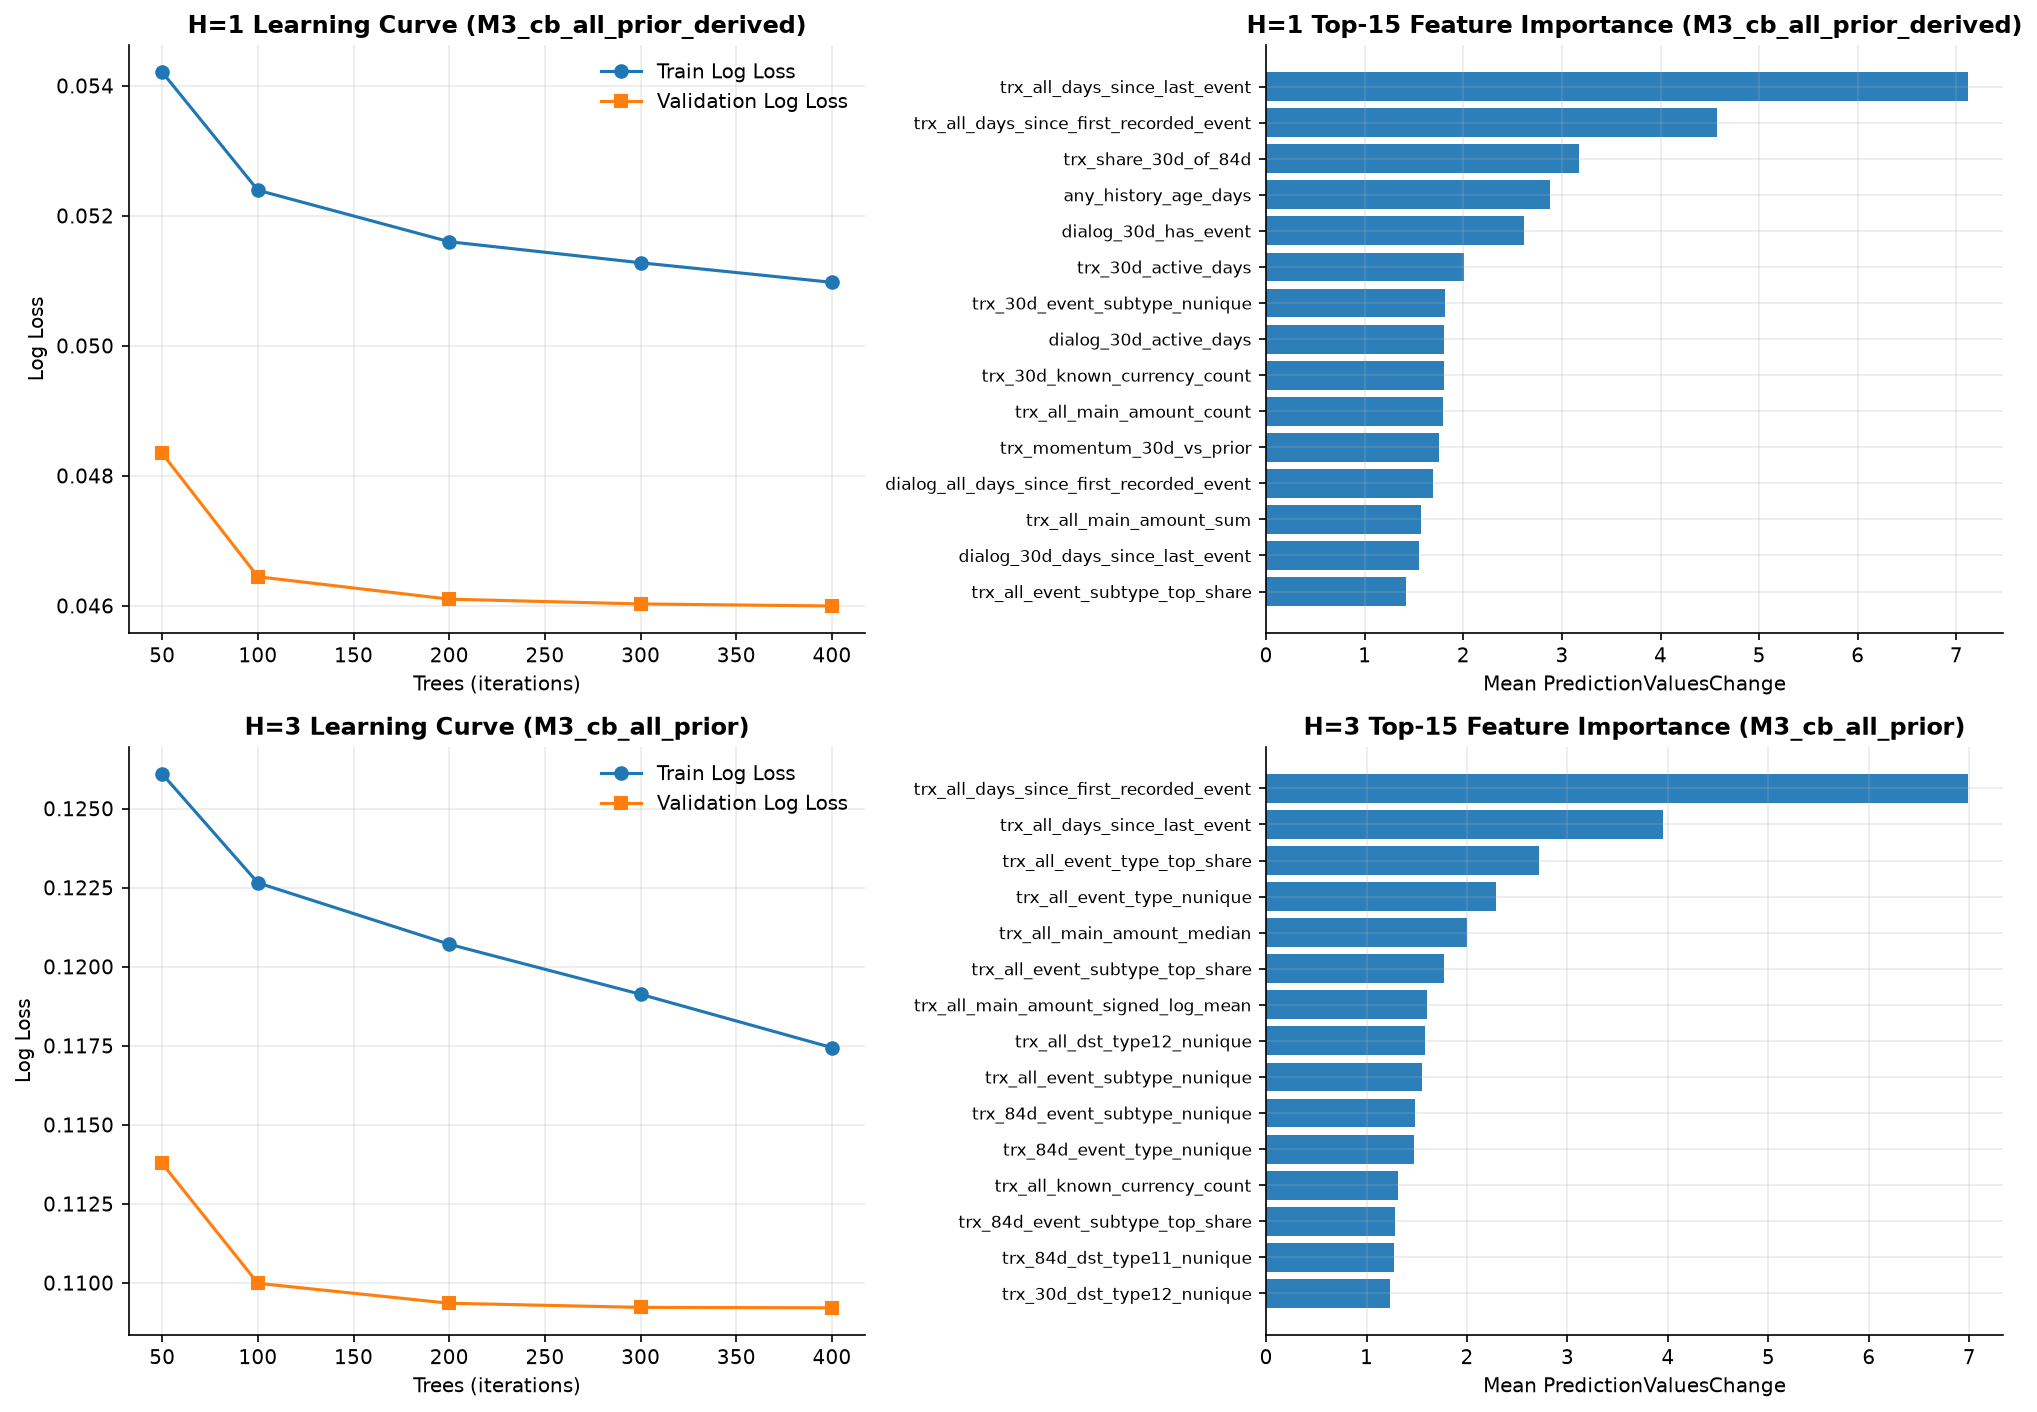

=== H=1 Top-15 Features (M3_cb_all_prior_derived) ===


,feature,importance,in_top50
201,trx_all_days_since_last_event,7.116,True
200,trx_all_days_since_first_recorded_event,4.576,True
249,trx_share_30d_of_84d,3.178,True
1,any_history_age_days,2.879,False
7,dialog_30d_has_event,2.616,True
95,trx_30d_active_days,2.009,True
109,trx_30d_event_subtype_nunique,1.818,True
3,dialog_30d_active_days,1.803,False
120,trx_30d_known_currency_count,1.802,False
223,trx_all_main_amount_count,1.789,False


=== H=3 Top-15 Features (M3_cb_all_prior) ===


,feature,importance,in_top50
193,trx_all_days_since_first_recorded_event,6.985,True
194,trx_all_days_since_last_event,3.956,True
205,trx_all_event_type_top_share,2.716,False
204,trx_all_event_type_nunique,2.288,True
219,trx_all_main_amount_median,1.997,True
202,trx_all_event_subtype_top_share,1.772,False
220,trx_all_main_amount_signed_log_mean,1.605,False
198,trx_all_dst_type12_nunique,1.581,False
201,trx_all_event_subtype_nunique,1.551,False
152,trx_84d_event_subtype_nunique,1.481,False


,horizon,experiment_id,n_features,mean_train_sec,mean_predict_sec,mean_model_kb,max_rss_mb
0,1,B0_prevalence,0,0.00,0.00,0.06,364.4
1,1,B1_heuristic_rf,2,0.00,0.00,0.04,391.4
2,1,B2_logreg_trx_full,148,18.88,0.48,4.46,1054.5
3,1,M2_cb_trx_84d,49,41.60,0.05,436.10,503.1
4,1,M2_cb_trx_full,148,77.13,0.13,447.98,821.1
5,1,M3_cb_all_221,221,98.04,0.18,449.80,1045.3
6,1,M3_cb_all_prior,238,99.67,0.19,450.59,1113.9
7,1,M3_cb_all_prior_derived,252,103.41,0.20,450.49,1154.1
8,1,M3_cb_full_cold_fallback,252,101.55,0.24,451.50,1152.9
9,1,M3_cb_trx_meta,199,92.38,0.16,450.57,981.4


In [6]:
from propensity_model.features import TOP50_FEATURES

lc_df = pd.read_csv(METRIC_DIR / "learning_curves.csv")
fi_df = pd.read_csv(METRIC_DIR / "feature_importance.csv")
op_df = pd.read_csv(METRIC_DIR / "operational_stats.csv")
top50_set = set(TOP50_FEATURES)

display(Image(filename=str(FIG_DIR / "08_learning_curves_and_importance.png")))

for h in (1, 3):
    w = manifest["winners"][f"h{h}"]
    top = fi_df[(fi_df["horizon"] == h) & (fi_df["experiment_id"] == w)].groupby("feature", as_index=False)["importance"].mean().sort_values("importance", ascending=False).head(15)
    top["in_top50"] = top["feature"].isin(top50_set)
    print(f"=== H={h} Top-15 Features ({w}) ===")
    display(top.round(3))

op_summary = op_df[op_df["stage"] == "validation"].groupby(["horizon", "experiment_id"], as_index=False).agg(
    n_features=("n_features", "first"),
    mean_train_sec=("train_seconds", "mean"),
    mean_predict_sec=("predict_seconds", "mean"),
    mean_model_kb=("model_bytes", lambda s: s.mean() / 1024.0),
    max_rss_mb=("rss_mb", "max"),
)
display(op_summary.round(2))


**Phân tích mục 6:**
- Cột `in_top50 = False` chỉ đích danh các đặc trưng ngoài bộ 50 đã tạo nên phần tăng **AP** (`+0,0030`) và **ROC-AUC** (`+0,0016` đến `+0,0036`) của `Full-252` trên Validation — đáng chú ý là **không phải** các biến thời gian ẩn `*_source_window_overlap_days`, mà là các tín hiệu hành vi thực thụ:
  - Cho `H=1`: `any_history_age_days` (tuổi lịch sử tổng hợp 3 nguồn), `dialog_30d_active_days`, `dialog_all_days_since_first_recorded_event`, `trx_all_event_subtype_top_share`, `trx_all_main_amount_sum`.
  - Cho `H=3`: độ tập trung & đa dạng tiểu loại dài hạn (`trx_all_event_type_top_share`, `trx_all_event_subtype_top_share`, `trx_all/84d_event_subtype_nunique`), đa dạng kênh đích (`trx_all/30d_dst_type12_nunique`, `trx_84d_dst_type11_nunique`), và chiều dòng tiền dài hạn (`trx_all_main_amount_signed_log_mean`).
- Chi phí vận hành: `Full-252` tốn thời gian huấn luyện gấp ~`1,8–2,0×` (`~103s/fold` cho `H=1`, `~44s/fold` cho `H=3`) và RAM gấp ~`2,2×` (`1.154 MB` vs `515 MB`) so với `Top-50`, nhưng vẫn hoàn toàn khả thi trên máy CPU 2 nhân / RAM 8 GB.


## 7. Tổng kết & Khuyến nghị Chọn Cấu hình Chính

1. **Tổng hợp hiệu năng 2 bộ đặc trưng (`Top-50` vs `Full-252`):**
   - Cả 2 bộ đều tái lập đầy đủ và ổn định trên toàn bộ 12 tháng dữ liệu (`2021`→`< cutoff`, burn-in `2022-02..04`, embargo 2 tháng cho `H=3`, calibration tháng `12/2022` cho `H=1`).
   - Kết quả kiểm định paired bootstrap ở Mục 4 cho phép chọn lựa minh bạch dựa trên dữ liệu: nếu chênh lệch giữa `Full-252` và `Top-50` nằm trong khoảng bất định hoặc rất nhỏ so với mức tăng thời gian huấn luyện (~`2–3×`), **`Top-50`** là ứng viên baseline gọn nhẹ, nhanh và ít rủi ro drift hơn; ngược lại, những biến nằm ngoài Top-50 nhưng có Feature Importance cao trong `Full-252` có thể được bổ sung chọn lọc để tạo bộ **Top-60/70 tối ưu** ở bước tinh chỉnh kế tiếp.
2. **Định hướng tối ưu sau Baseline:**
   - Tinh chỉnh riêng số cây & regularization cho `H=3` (dùng inner temporal early-stopping hoặc `iterations ≈ 200–250` do dữ liệu train nhỏ hơn).
   - Đối chứng lưới `class_weight` vừa phải (`1, 3, 5`) và bổ sung đặc trưng cấp raw chưa có trong `processed/propensity.parquet` (như `et_new_cells_T1` ở Slide F và `dialog` embedding PCA 32/64 chiều học trên train).
